# Lending Club Loan Data Analysis
**Course-End Project, Deep Learning with Keras and TensorFlow**

Objective: predict whether a loan will be **not fully paid** (`not.fully.paid = 1`) using historical Lending Club data (2007-2015). Tasks: feature transformation, EDA, correlation-based feature selection, and a Keras deep learning model.

*CPU-only run; training is short.*

In [1]:
import os, json, warnings, random
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt, seaborn as sns
os.environ['TF_CPP_MIN_LOG_LEVEL']='3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve, recall_score,
                             precision_score, accuracy_score, f1_score, classification_report)
SEED=42; np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)
os.makedirs('screenshots', exist_ok=True)
def save(name): plt.savefig(f'screenshots/{name}.png', dpi=110, bbox_inches='tight')
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## Load the data

In [2]:
df = pd.read_csv('data/loan_data.csv')
print(df.shape, '| nulls:', int(df.isnull().sum().sum()))
df.head()

(9578, 14) | nulls: 0


,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [3]:
df.describe().T.round(2)[['mean','std','min','max']]

,mean,std,min,max
credit.policy,0.80,0.40,0.00,1.00
int.rate,0.12,0.03,0.06,0.22
installment,319.09,207.07,15.67,940.14
log.annual.inc,10.93,0.61,7.55,14.53
dti,12.61,6.88,0.00,29.96
fico,710.85,37.97,612.00,827.00
days.with.cr.line,4560.77,2496.93,178.96,17639.96
revol.bal,16913.96,33756.19,0.00,1207359.00
revol.util,46.80,29.01,0.00,119.00
inq.last.6mths,1.58,2.20,0.00,33.00


The data has 9,578 loans, 13 features and the label `not.fully.paid`; there are no missing values.

## Task 1: Feature transformation (categorical to numerical)
`purpose` is the only categorical column. It is converted to discrete integer codes (label encoding), as the task asks; a one-hot version is used later for the neural network, which should not read arbitrary integer codes as an order.

In [4]:
print(df['purpose'].value_counts())
df_enc = df.copy()
df_enc['purpose_code'] = df_enc['purpose'].astype('category').cat.codes
df_enc[['purpose','purpose_code']].drop_duplicates().sort_values('purpose_code')

purpose
debt_consolidation    3957
all_other             2331
credit_card           1262
home_improvement       629
small_business         619
major_purchase         437
educational            343
Name: count, dtype: int64


,purpose,purpose_code
7,all_other,0
1,credit_card,1
0,debt_consolidation,2
46,educational,3
8,home_improvement,4
15,major_purchase,5
13,small_business,6


## Task 2: Exploratory data analysis

Default rate (not fully paid): 16.01%  | counts: {0: 8045, 1: 1533}

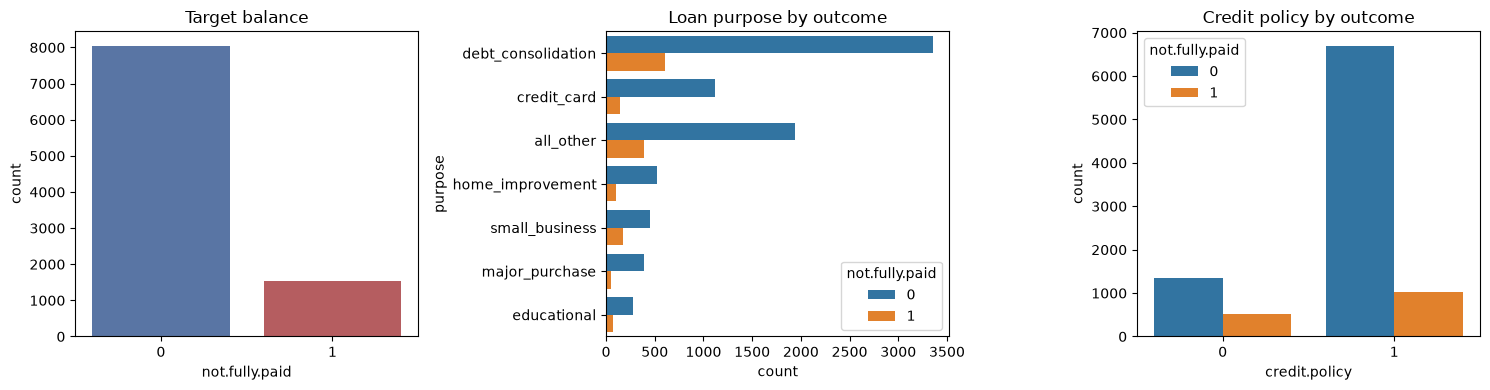

In [5]:
tgt = df['not.fully.paid']
print('Default rate (not fully paid): %.2f%%  | counts: %s' % (tgt.mean()*100, tgt.value_counts().to_dict()))
fig,ax=plt.subplots(1,3,figsize=(15,4))
sns.countplot(x='not.fully.paid', data=df, ax=ax[0], palette=['#4c72b0','#c44e52']); ax[0].set_title('Target balance')
sns.countplot(y='purpose', hue='not.fully.paid', data=df, ax=ax[1]); ax[1].set_title('Loan purpose by outcome')
sns.countplot(x='credit.policy', hue='not.fully.paid', data=df, ax=ax[2]); ax[2].set_title('Credit policy by outcome')
plt.tight_layout(); save('01_target_purpose_policy'); plt.show()

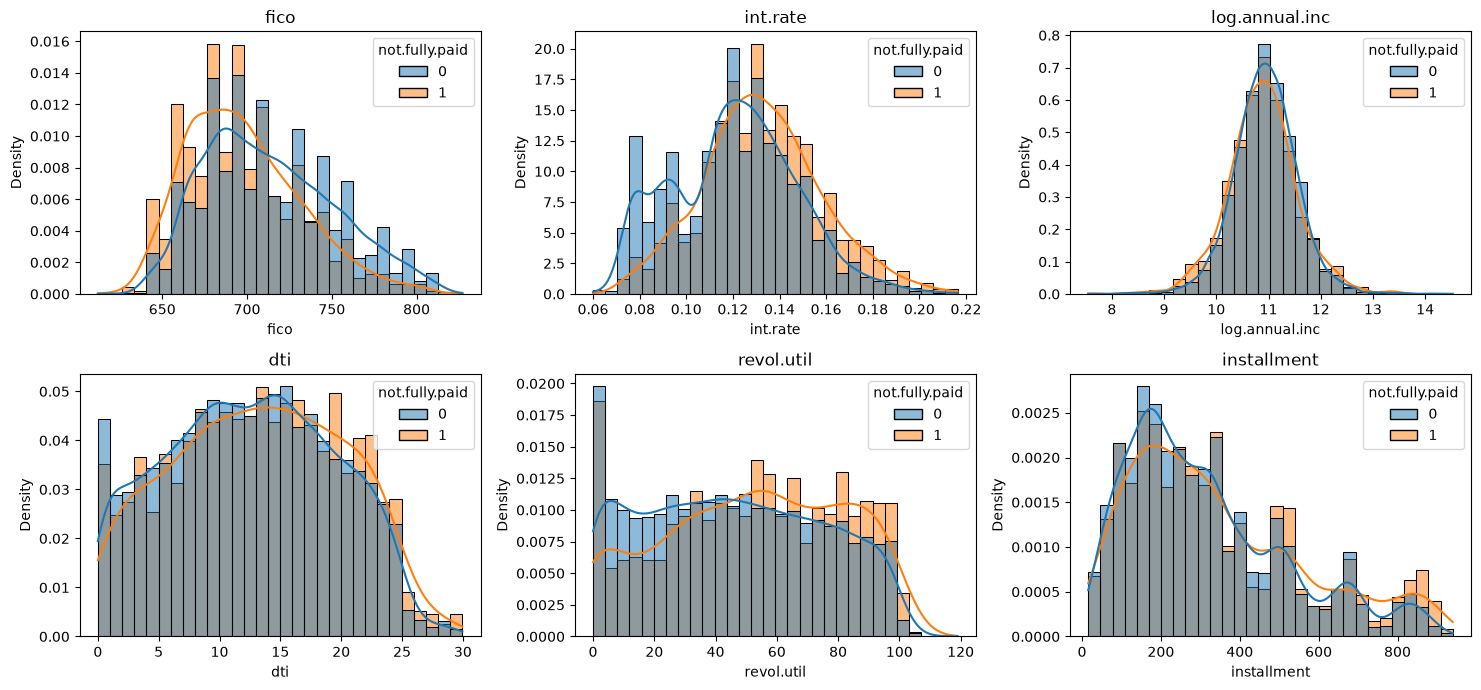

In [6]:
fig,ax=plt.subplots(2,3,figsize=(15,7))
for a,c in zip(ax.ravel(), ['fico','int.rate','log.annual.inc','dti','revol.util','installment']):
    sns.histplot(data=df, x=c, hue='not.fully.paid', bins=30, kde=True, stat='density', common_norm=False, ax=a); a.set_title(c)
plt.tight_layout(); save('02_feature_distributions'); plt.show()

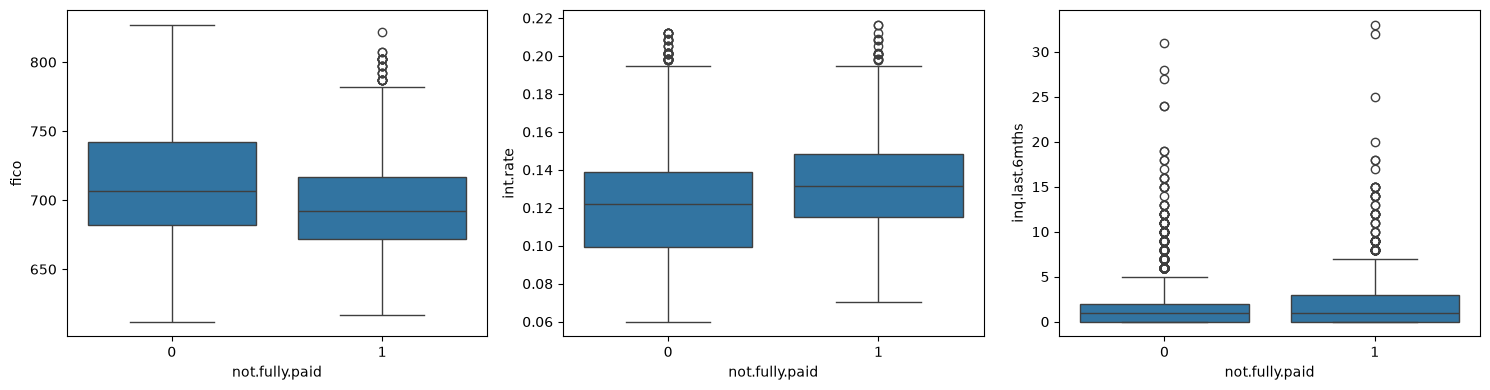

purpose
small_business        0.278
educational           0.201
home_improvement      0.170
all_other             0.166
debt_consolidation    0.152
credit_card           0.116
major_purchase        0.112
Name: not.fully.paid, dtype: float64


In [7]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
sns.boxplot(x='not.fully.paid', y='fico', data=df, ax=ax[0]); sns.boxplot(x='not.fully.paid', y='int.rate', data=df, ax=ax[1]); sns.boxplot(x='not.fully.paid', y='inq.last.6mths', data=df, ax=ax[2])
plt.tight_layout(); save('03_boxplots'); plt.show()
print(df.groupby('purpose')['not.fully.paid'].mean().sort_values(ascending=False).round(3))

Observations (see the output above): only ~16% of loans are not fully paid (imbalanced). The plots compare FICO, interest rate and inquiries by outcome, and the table gives the default rate per purpose.

## Task 3: Additional feature engineering (correlation)
We look at the correlation matrix of the numeric features and drop one feature from each strongly correlated pair (|r| > 0.7).

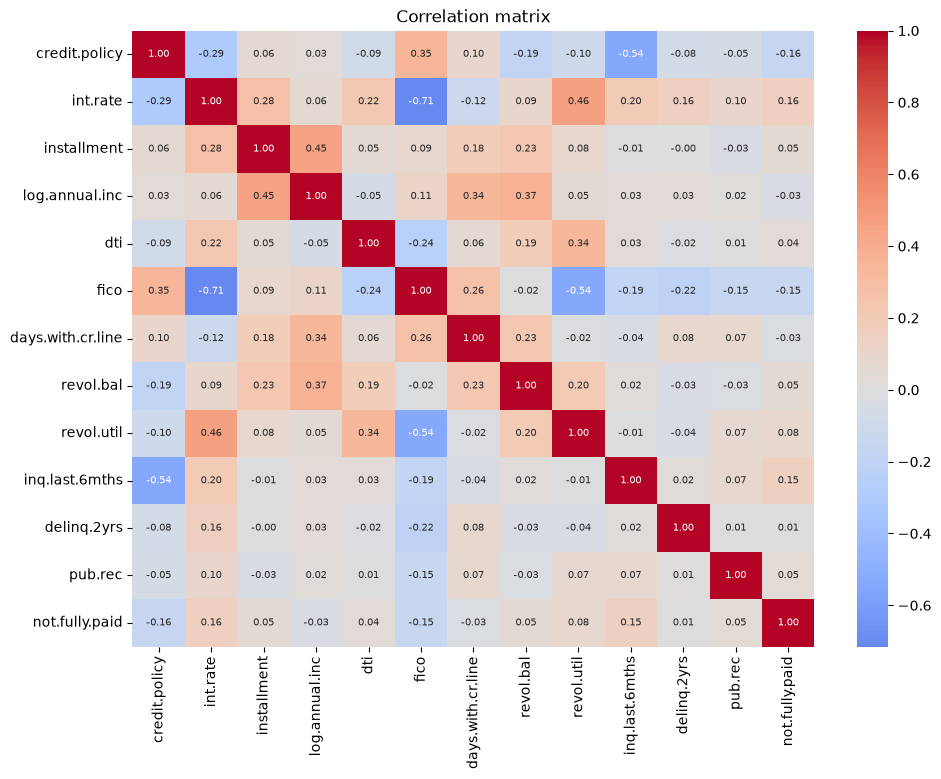

Strongly correlated pairs (|r|>0.7): [('int.rate', 'fico', np.float64(0.715))]


In [8]:
num = df.drop(columns=['purpose'])
corr = num.corr()
plt.figure(figsize=(11,8)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size':7}); plt.title('Correlation matrix'); save('04_correlation_heatmap'); plt.show()
feat_corr = num.drop(columns='not.fully.paid').corr().abs()
pairs = [(a,b,round(feat_corr.loc[a,b],3)) for i,a in enumerate(feat_corr.columns) for b in feat_corr.columns[i+1:] if feat_corr.loc[a,b]>0.7]
print('Strongly correlated pairs (|r|>0.7):', pairs)

In [9]:
# drop the member of each pair that is less correlated with the target
tcorr = num.corr()['not.fully.paid'].abs()
drop = sorted({(b if tcorr[a]>=tcorr[b] else a) for a,b,_ in pairs})
print('Dropping:', drop)
keep = [c for c in num.columns if c not in drop]
print('Remaining numeric features:', [c for c in keep if c!='not.fully.paid'])

Dropping: ['fico']
Remaining numeric features: ['credit.policy', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec']


`int.rate` and `fico` are strongly (negatively) correlated, as expected (riskier borrowers get higher rates). Only one of the pair is kept, which removes redundant information from the model inputs.

## Task 4: Modeling with Keras / TensorFlow
Inputs: the retained numeric features plus one-hot `purpose`, standardized. Stratified 80/20 split; because only 16% are positives, **class weights** are used during training. A dense network with dropout is trained with early stopping.

In [10]:
X = pd.concat([num[keep].drop(columns='not.fully.paid'), pd.get_dummies(df['purpose'], prefix='purpose', dtype=int)], axis=1)
y = df['not.fully.paid'].values
X_tr, X_te, y_tr, y_te = train_test_split(X.values.astype('float32'), y, test_size=0.2, stratify=y, random_state=SEED)
sc = StandardScaler().fit(X_tr); X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)
cw = {0: len(y_tr)/(2*(y_tr==0).sum()), 1: len(y_tr)/(2*(y_tr==1).sum())}
print(X_tr.shape, X_te.shape, 'class weights', {k:round(v,2) for k,v in cw.items()})

(7662, 18) (1916, 18) class weights {0: np.float64(0.6), 1: np.float64(3.12)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,841 (15.00 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 0 (0.00 B)

Epochs run: 11


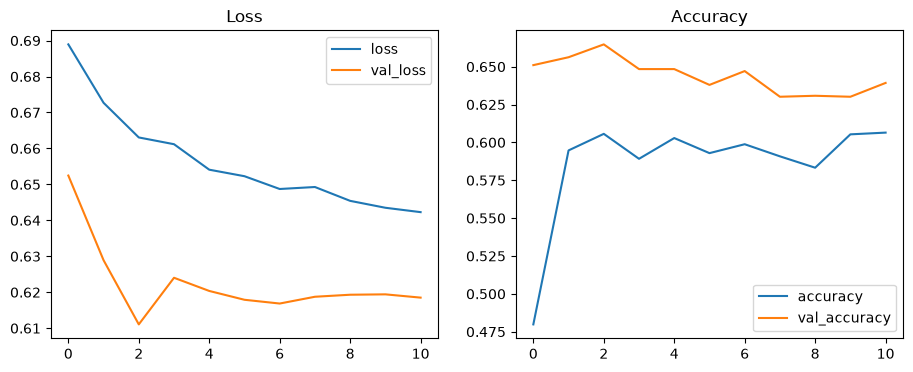

In [11]:
model = keras.Sequential([layers.Input(shape=(X_tr.shape[1],)),
    layers.Dense(64, activation='relu'), layers.Dropout(0.3),
    layers.Dense(32, activation='relu'), layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy', keras.metrics.AUC(name='auc')])
model.summary()
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
hist = model.fit(X_tr, y_tr, validation_split=0.2, epochs=100, batch_size=64, class_weight=cw, callbacks=[es], verbose=0)
print('Epochs run:', len(hist.history['loss']))
h = pd.DataFrame(hist.history)
fig,ax=plt.subplots(1,2,figsize=(11,4)); h[['loss','val_loss']].plot(ax=ax[0], title='Loss'); h[['accuracy','val_accuracy']].plot(ax=ax[1], title='Accuracy'); save('05_training_curves'); plt.show()

### Evaluation on the test set

                precision    recall  f1-score   support

    Fully paid      0.890     0.682     0.772      1609
Not fully paid      0.251     0.557     0.346       307

      accuracy                          0.662      1916
     macro avg      0.570     0.620     0.559      1916
  weighted avg      0.787     0.662     0.704      1916

ROC-AUC: 0.6725


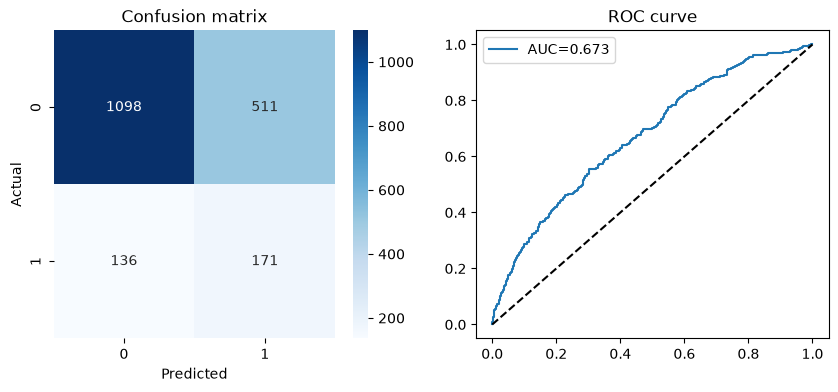

In [12]:
prob = model.predict(X_te, verbose=0).ravel(); pred=(prob>=0.5).astype(int)
print(classification_report(y_te, pred, target_names=['Fully paid','Not fully paid'], digits=3))
auc = roc_auc_score(y_te, prob); print('ROC-AUC: %.4f' % auc)
fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.heatmap(confusion_matrix(y_te,pred), annot=True, fmt='d', cmap='Blues', ax=ax[0]); ax[0].set_title('Confusion matrix'); ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')
fpr,tpr,_=roc_curve(y_te,prob); ax[1].plot(fpr,tpr,label=f'AUC={auc:.3f}'); ax[1].plot([0,1],[0,1],'k--'); ax[1].legend(); ax[1].set_title('ROC curve')
save('06_confusion_roc'); plt.show()

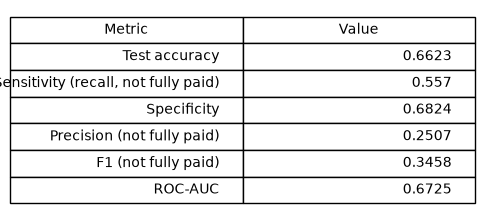

,Metric,Value
0,Test accuracy,0.6623
1,"Sensitivity (recall, not fully paid)",0.5570
2,Specificity,0.6824
3,Precision (not fully paid),0.2507
4,F1 (not fully paid),0.3458
5,ROC-AUC,0.6725


In [13]:
tn,fp,fn,tp = confusion_matrix(y_te,pred).ravel()
res = pd.DataFrame({'Metric':['Test accuracy','Sensitivity (recall, not fully paid)','Specificity','Precision (not fully paid)','F1 (not fully paid)','ROC-AUC'],
  'Value':[accuracy_score(y_te,pred), tp/(tp+fn), tn/(tn+fp), precision_score(y_te,pred), f1_score(y_te,pred), auc]}).round(4)
json.dump({r.Metric:float(r.Value) for r in res.itertuples()}, open('metrics.json','w'), indent=1)
fig,ax=plt.subplots(figsize=(6,2.6)); ax.axis('off'); t=ax.table(cellText=res.values, colLabels=res.columns, loc='center'); t.scale(1,1.6); t.auto_set_font_size(False); t.set_fontsize(10)
save('07_metrics_table'); plt.show(); res

## Conclusions
* About 16% of loans are not fully paid, so the data is imbalanced; class weights were used.
* Correlated features (`int.rate`/`fico`) were pruned before modeling.
* The Keras network with class weights trades accuracy for sensitivity; its ROC-AUC (table above) shows modest signal. Better results would need more features or a boosted-tree comparison.